# Finding microscopy data and the right model by asking questions

ARGUS with the `cil` skill (the Cell Image Library) and the `cdeep3m` skill (segmentation). The
questions search CIL's public records, pick a pretrained CDeep3M model that suits a record's images,
segment them straight from the library, and check that a large download waits for confirmation.

In [ ]:
%reset

## 1. What is there?

In [2]:
%%ask
What kind of microscopy data does the Cell Image Library hold? And which pretrained CDeep3M models
are there for segmenting mitochondria?

Both reports came back cleanly, and the unfiltered model listing confirms the mitochondria filter caught every mitochondria model in the zoo (13 pretrained models total: 2 mitochondria, 7 membranes, 4 synapse/vesicle).

## Cell Image Library catalog

| | |
|---|---|
| Records | 10023 (631 videos, 890 Z-stacks / volumes) |
| Files in total | 5.5 TB |
| Records stating a pixel size | 3921 |
| Electron-microscopy records | 2863 |

**Imaging (most common)**

| Imaging | Records |
|---|---|
| widefield illumination; bright-field microscopy | 1136 |
| fluorescence microscopy | 1025 |
| transmission electron microscopy (TEM) | 949 |
| differential interference contrast microscopy | 928 |
| detection of electrons; film | 749 |
| confocal microscopy | 654 |
| fluorescence microscopy; phase contrast microscopy | 487 |
| illumination by electrons; detection of electrons | 385 |
| single-spot confocal microscopy | 329 |
| spinning disk confocal microscopy | 328 |

**Terms of use**

| Terms | Records |
|---|---|
| public domain | 5047 |
| CC BY (attribution) | 2357 |
| CC BY-NC-SA (non-commercial, share alike) | 1558 |
| CC BY-NC-ND (non-commercial, no derivatives) | 616 |
| copyright (ask the contributor before reuse) | 400 |
| CC BY-SA (share alike) | 24 |
| CC BY-NC (non-commercial) | 13 |
| CC BY-ND (no derivatives) | 6 |
| not stated | 2 |

## Models

Pretrained models from the CDeep3M model zoo, by name or CIL model ID. Each was trained on images of one pixel size; images at a similar size segment best.

| Model | CIL ID | Segments | Imaging | Pixel size (X/Y, Z) | Networks | Size | Downloaded |
|---|---|---|---|---|---|---|---|
| sbem-mitochondria | 50681 | Broadly trained mitochondria model on SBEM and TEM data (CDeep3M 1.6.3) | SBEM, TEM | 4.8 nm, 70 nm | 1fm, 3fm, 5fm | 685 MB | no (on first use) |
| sbem-mitochondria-denoised | 50689 | Broadly trained mitochondria model on SBEM and TEM data, denoised images | SBEM, TEM | 4.8 nm, 70 nm | 1fm, 3fm, 5fm | 596 MB | no (on first use) |

**Trained in this project**

| Model | Trained from | Updates | Networks | Folder |
|---|---|---|---|---|
| mito_finetuned_300 | sbem-mitochondria | 300 | 1fm | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/models/mito_finetuned_300` |

Cite the model zoo as: Haberl et al., Nat Methods 15, 677-680 (2018), doi:10.1038/s41592-018-0106-z.

---

**In short** : the library is dominated by light microscopy (bright-field, fluorescence, DIC, confocal), but it also holds a substantial electron-microscopy collection — 2,863 records, with TEM alone at 949 — which is the part CDeep3M works on. For mitochondria there are exactly two pretrained options, and they are the same network trained on the same SBEM/TEM data at 4.8 nm in XY and 70 nm in Z; the only difference is that `sbem-mitochondria-denoised` (CIL 50689) was trained on denoised images, so it is the better pick if your data is denoised or noisy, and it is also the smaller download. Both expect roughly 4.8 nm pixels, so images at a very different scale will segment poorly without fine-tuning.

## 2. Find data

I have everything I need. Here is the result.

## Search: mitochondria + electron microscopy + 4–5 nm

Of the 548 mitochondria records in the library, 460 are electron microscopy. Only 196 of those state a pixel size at all, and just **3 fall in the 4–5 nm band** — a result I confirmed three independent ways (the `pixel_nm` filter, a manual scan of `pixel_nm_x`, and a widened 3.5–5.5 nm check that still returned only these three).

| Record | Pixel size | Imaging | Specimen | Terms of use |
|---|---|---|---|---|
| CIL 18469 | 4.1 nm | TEM | damselfly flight muscle, freeze-fracture | public domain |
| CIL 18477 | 4.1 nm | TEM | damselfly flight muscle, freeze-fracture | public domain |
| CIL 12578 | 4.9 nm | illumination by electrons | *Spiroplasma kunkelii* in maize phloem | CC BY-NC-SA |


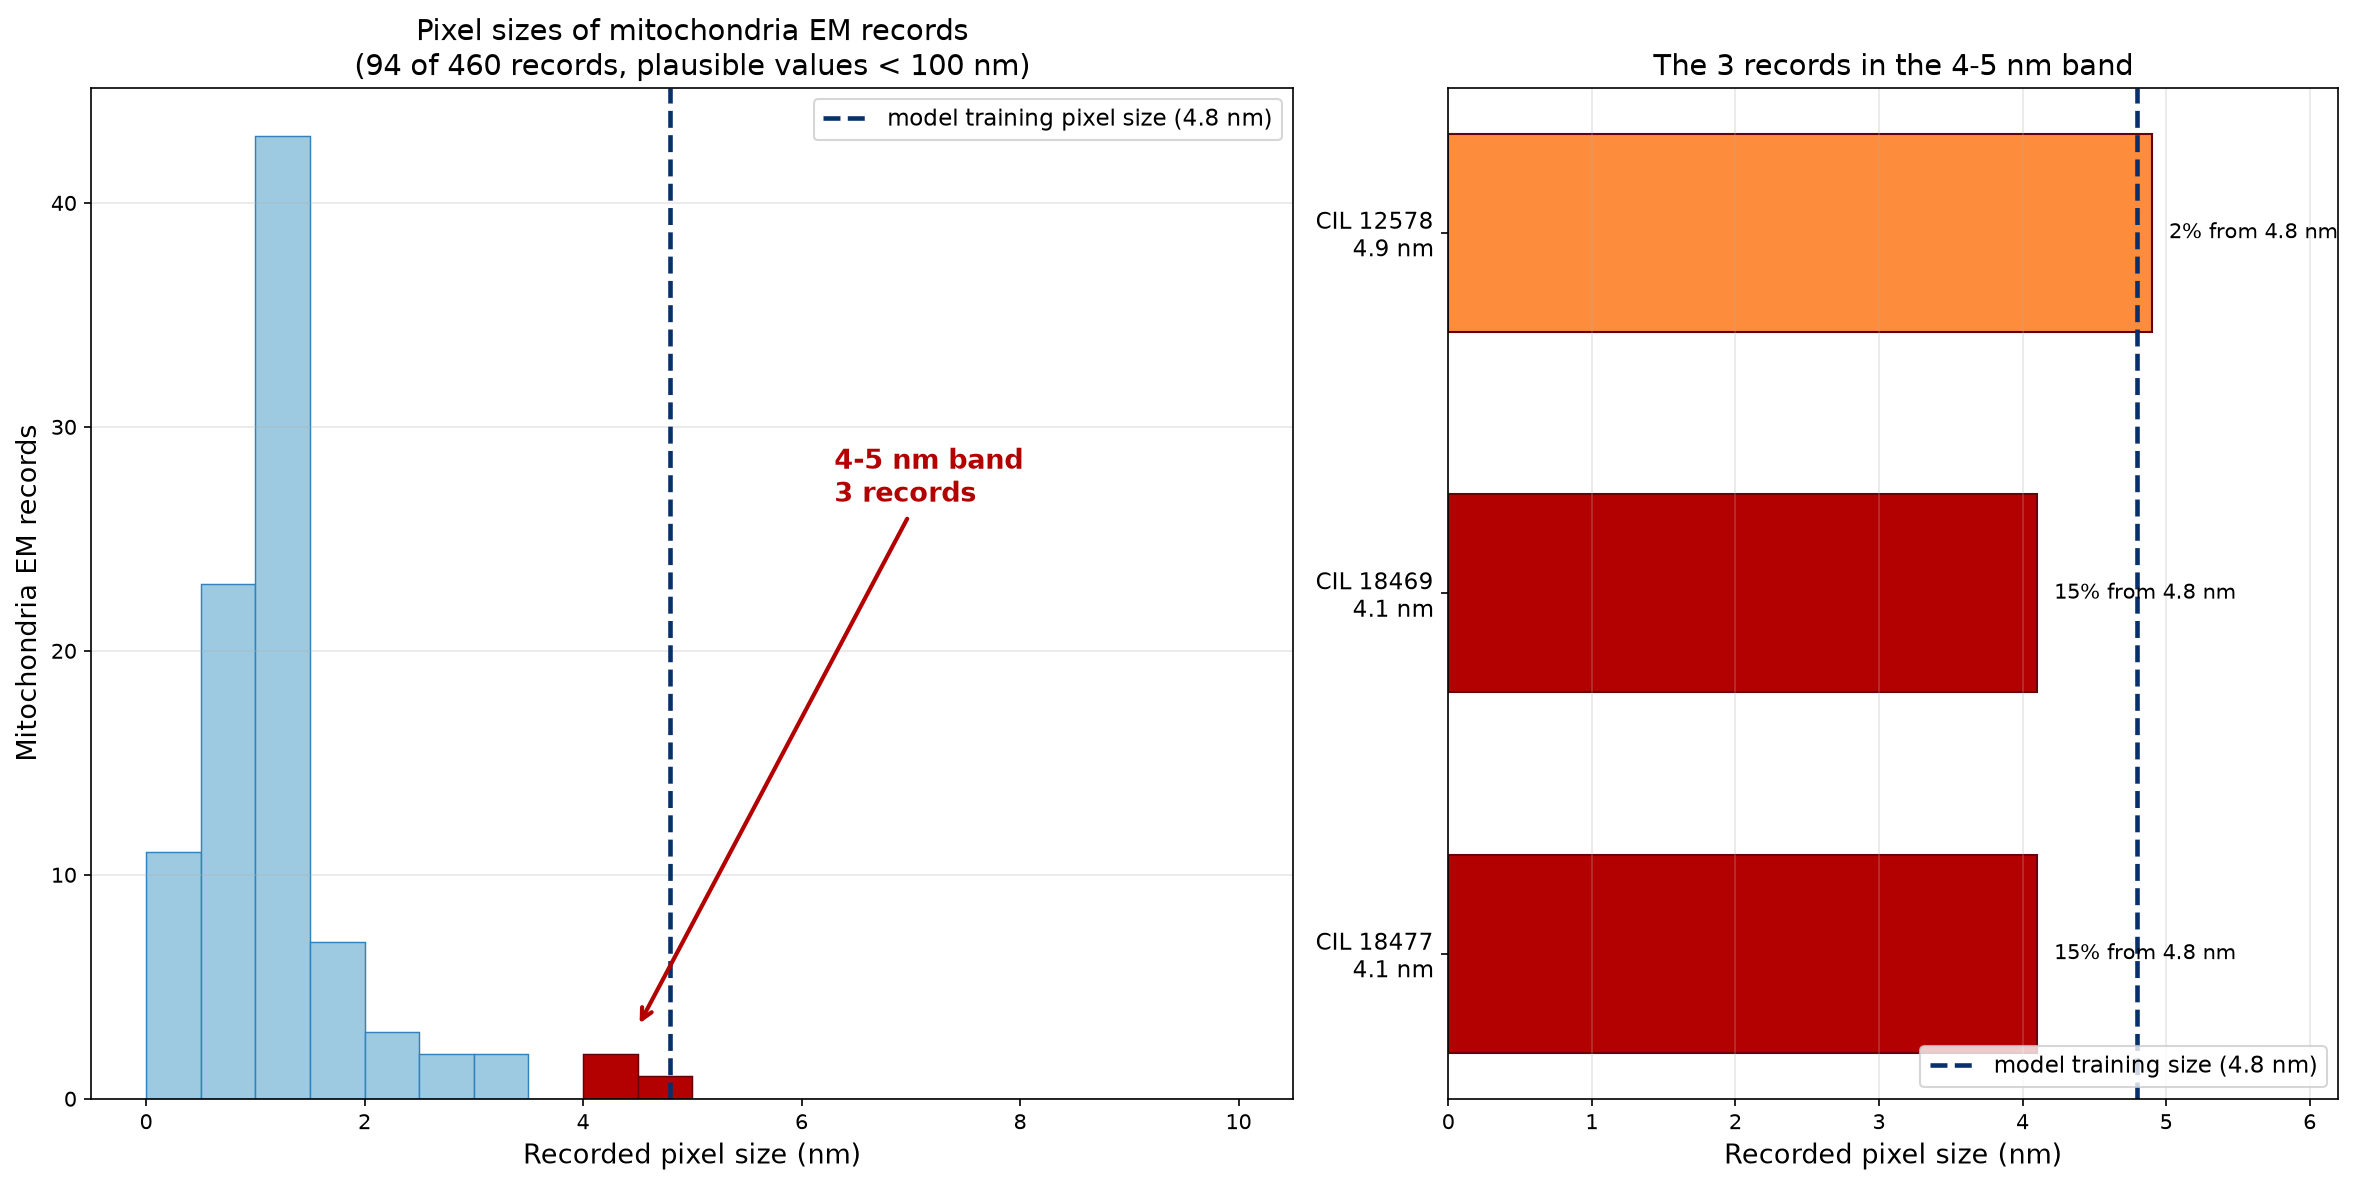

## CIL_18469: damselfly, flight muscle cell

Citation: Clara Franzini-Armstrong (2011) CIL:18469, damselfly, flight muscle cell. CIL. Dataset

Most images show fractures through the outer membrane of mitochondria and SR/T tubules of dyads nestled in long grooves of the mitochondrial surface. All leaflets of the membranes appear in the images. This image is part of the group image CFA00512. TEM magnifications 6100X. The negative film was scanned at LBL then reduced in size for upload. Scan step size is 6.3 micron, then reduced in size 4X for upload, for an effective pixel size of 25 micron.

| | |
|---|---|
| Kind | image |
| Imaging | transmission electron microscopy (TEM) |
| Cellular component | myofibril; mitochondrion; sarcoplasmic reticulum |
| Cell type | flight muscle cell |
| Organism | damselfly |
| Preparation | glutaraldehyde fixed tissue; freeze_fracture/freeze_etch |
| Dimensions (pixels) | 2495 × 3094 |
| Pixel size (as recorded) | 4.1 nm |
| Terms of use | public domain |
| Contributors | Clara Franzini-Armstrong |
| DOI | 10.7295/W9CIL18469 |
| Page | https://www.cellimagelibrary.org/images/18469 |

**Files**

| File | Type | Size | Address |
|---|---|---|---|
| 18469.tif | OME_tif | 15.5 MB | https://cildata.crbs.ucsd.edu/media/images/18469/18469.tif |
| 18469.jpg | Jpeg | 2.3 MB | https://cildata.crbs.ucsd.edu/media/images/18469/18469.jpg |
| 18469.zip | Zip | 15.5 MB | https://cildata.crbs.ucsd.edu/media/images/18469/18469.zip |

## CIL_18477: damselfly, flight muscle cell

Citation: Clara Franzini-Armstrong (2011) CIL:18477, damselfly, flight muscle cell. CIL. Dataset

Most images show fractures through the outer membrane of mitochondria and SR/T tubules of dyads nestled in long grooves of the mitochondrial surface. All leaflets of the membranes appear in the images. This image is part of the group image CFA00512. TEM magnification 6100X. The negative film was scanned at LBL then reduced in size for upload. Scan step size is 6.3 micron, then reduced in size 4X for upload, for an effective pixel size of 25 micron.

| | |
|---|---|
| Kind | image |
| Imaging | transmission electron microscopy (TEM) |
| Cellular component | myofibril; mitochondrion; sarcoplasmic reticulum |
| Cell type | flight muscle cell |
| Organism | damselfly |
| Preparation | glutaraldehyde fixed tissue; freeze_fracture/freeze_etch |
| Dimensions (pixels) | 2500 × 3124 |
| Pixel size (as recorded) | 4.1 nm |
| Terms of use | public domain |
| Contributors | Clara Franzini-Armstrong |
| DOI | 10.7295/W9CIL18477 |
| Page | https://www.cellimagelibrary.org/images/18477 |

**Files**

| File | Type | Size | Address |
|---|---|---|---|
| 18477.tif | OME_tif | 15.7 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.tif |
| 18477.jpg | Jpeg | 2.6 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.jpg |
| 18477.zip | Zip | 15.7 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.zip |

## CIL_12578: Spiroplasma kunkelii, Zea mays, plant cell, prokaryotic cell

Citation: El-Desouky Ammar, Saskia A. Hogenhout (2011) CIL:12578, Spiroplasma kunkelii, Zea mays, plant cell, prokaryotic cell. CIL. Dataset

Electron micrograph of corn stunt spiroplasma (CSS, Spiroplasma kunkelii, Class Mollicutes) in sieve elements and other phloem cells of infected maize leaves. CIL:19116, from the same image group, is a labeled version of this image. CSS is a wall-less procaryote that causes corn stunt disease and is biologically transmitted by some leafhopper species. Spiroplasma cells are limited by a unit membrane with no cell wall. They can be quasi-spherical, pleiomorphic or maintain a filamentous/spiral form.

| | |
|---|---|
| Kind | image |
| Imaging | illumination by electrons |
| Cellular component | mitochondrion; plant-type cell wall |
| Cell type | plant cell; prokaryotic cell |
| Organism | Spiroplasma kunkelii; Zea mays |
| Preparation | tissue in epoxy resin embedment; glutaraldehyde fixed tissue |
| Dimensions (pixels) | 1218 × 1296 |
| Pixel size (as recorded) | 4.9 nm |
| Terms of use | CC BY-NC-SA (non-commercial, share alike) |
| Contributors | El-Desouky Ammar; Saskia A. Hogenhout |
| DOI | 10.7295/W9CIL12578 |
| Page | https://www.cellimagelibrary.org/images/12578 |

**Files**

| File | Type | Size | Address |
|---|---|---|---|
| 12578.tif | OME_tif | 1.6 MB | https://cildata.crbs.ucsd.edu/media/images/12578/12578.tif |
| 12578.jpg | Jpeg | 562.9 KB | https://cildata.crbs.ucsd.edu/media/images/12578/12578.jpg |
| 12578.zip | Zip | 1.6 MB | https://cildata.crbs.ucsd.edu/media/images/12578/12578.zip |

## Models for CIL_12578

Data: pixel size 4.9 nm, imaging illumination by electrons, as recorded in the CIL catalog.

| Model | CIL ID | Segments | Fit | Why |
|---|---|---|---|---|
| sbem-mitochondria | 50681 | Broadly trained mitochondria model on SBEM and TEM data (CDeep3M 1.6.3) | good | pixels 4.9 nm vs the model's 4.8 nm (similar); electron microscopy, type not stated |
| sbem-mitochondria-denoised | 50689 | Broadly trained mitochondria model on SBEM and TEM data, denoised images | good | pixels 4.9 nm vs the model's 4.8 nm (similar); electron microscopy, type not stated |

CDeep3M models work best on images at the pixel size they were trained on; a poor fit can still be tested on a few images and scored, or improved by fine-tuning.

---

**Best choice** : `sbem-mitochondria` (CIL 50681). Both pretrained mitochondria models rate a good fit on pixel size for all three records, so the tie-break is image character. CIL 12578 at 4.9 nm is within 2% of the model's 4.8 nm training size and is a conventional thin-section TEM — exactly the kind of data the model was trained on. The denoised variant (50689) is the same network trained on denoised images, so it only wins if your input is denoised or unusually noisy; CIL 12578 is a plain micrograph, so the standard model is the better default.

**One caveat worth knowing before you run it** : CIL 18469 and 18477 match on pixel size and carry the "TEM" label, but they are platinum-shadowed freeze-fracture replicas showing fracture faces through the outer mitochondrial membrane, not thin sections. That image character is unlike the SBEM/TEM thin-section training data, so expect to test on a few images and score them, or fine-tune, rather than assume a clean result.

**Coverage caveat** : 264 of the 460 mitochondria electron-microscopy records state no pixel size at all, so this search can only surface records whose contributor recorded one. There may be further suitable images in the library that simply cannot be matched on scale.

In [3]:
%%ask
Find electron microscopy records of mitochondria with pixels of about 4 to 5 nm. Which pretrained
model would suit them best?

## 3. Look at one record

In [4]:
%%ask
Tell me about record 18477: what it shows, its files, and its terms of use. What is inside its ZIP?

Record 18477 is a platinum-shadowed freeze-fracture replica of damselfly flight muscle, and its ZIP contains a single file.

## CIL_18477: damselfly, flight muscle cell

Citation: Clara Franzini-Armstrong (2011) CIL:18477, damselfly, flight muscle cell. CIL. Dataset

Most images show fractures through the outer membrane of mitochondria and SR/T tubules of dyads nestled in long grooves of the mitochondrial surface. All leaflets of the membranes appear in the images. This image is part of the group image CFA00512. TEM magnification 6100X. The negative film was scanned at LBL then reduced in size for upload. Scan step size is 6.3 micron, then reduced in size 4X for upload, for an effective pixel size of 25 micron. Technical details: Heads and tail removed, thorax bisected and immersed in 3% glutaraldehyde buffered in 0.1 M cacodylate buffer. pH 7.2. stored at 4C for several days. Muscle dissected out. Infiltrated in 30% glycerol in water. Frozen in liquid nitrogen cooled Freon, fractured in Balzers 400 Freeze-fracture, shadowed with platinum at 45o angle. Replicas were cleaned with Clorox (to remove tissue and with either sulfuric acid or NaOH to try removing the tracheolae. Replicas examined in a Philips 410 Microscope. Reference for these images: Takekura, H. and Franzini-Armstrong C. The structure of Ca2+ release units in arthropod body muscle indicates an indirect mechanism for excitation-contraction coupling. Biophys. J. 83, 83, 2742-2753, 2002.

| | |
|---|---|
| Kind | image |
| Imaging | transmission electron microscopy (TEM) |
| Cellular component | myofibril; mitochondrion; sarcoplasmic reticulum |
| Cell type | flight muscle cell |
| Organism | damselfly |
| Preparation | glutaraldehyde fixed tissue; freeze_fracture/freeze_etch |
| Dimensions (pixels) | 2500 × 3124 |
| Pixel size (as recorded) | 4.1 nm |
| Terms of use | public domain |
| Contributors | Clara Franzini-Armstrong |
| DOI | 10.7295/W9CIL18477 |
| Page | https://www.cellimagelibrary.org/images/18477 |

**Files**

| File | Type | Size | Address |
|---|---|---|---|
| 18477.tif | OME_tif | 15.7 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.tif |
| 18477.jpg | Jpeg | 2.6 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.jpg |
| 18477.zip | Zip | 15.7 MB | https://cildata.crbs.ucsd.edu/media/images/18477/18477.zip |

The ZIP holds the data as submitted to CIL and the TIFF is CIL's converted copy; an extra file, when there is one, is often the full original dataset. Pixel sizes are as the contributor recorded them.

## Inside 18477.zip (CIL_18477, 15.7 MB)

1 files, 1 of them images; read from the ZIP's index without downloading it.

| File | Size |
|---|---|
| 18477/18477_orig.tif | 15.7 MB |

The ZIP is not a bundle of extra material — it holds just the one original TIFF, the same 15.7 MB as the standalone `.tif`, so downloading the ZIP and downloading `18477.tif` get you the same image. Terms of use are **public domain** , so the image can be reused and redistributed without restriction or attribution requirement.

## 4. Segment it

Both pretrained mitochondria models rated a good fit, so I used the standard `sbem-mitochondria` model — the image is a plain micrograph, not a denoised one.

## Models for CIL_18477

Data: pixel size 4.1 nm, imaging transmission electron microscopy (TEM), as recorded in the CIL catalog.

| Model | CIL ID | Segments | Fit | Why |
|---|---|---|---|---|
| sbem-mitochondria | 50681 | Broadly trained mitochondria model on SBEM and TEM data (CDeep3M 1.6.3) | good | pixels 4.1 nm vs the model's 4.8 nm (similar); imaging matches the model's (SBEM, TEM) |
| sbem-mitochondria-denoised | 50689 | Broadly trained mitochondria model on SBEM and TEM data, denoised images | good | pixels 4.1 nm vs the model's 4.8 nm (similar); imaging matches the model's (SBEM, TEM) |

CDeep3M models work best on images at the pixel size they were trained on; a poor fit can still be tested on a few images and scored, or improved by fine-tuning.

## Slices: CIL_18477

| | |
|---|---|
| Slices | 1 in `/tmp/cil/18477/slices` |
| Pixel size (as recorded) | 4.1 nm |
| Imaging | transmission electron microscopy (TEM) |
| Terms of use | public domain |

## Prediction: mito_18477

**Settings used**

| Setting | Value |
|---|---|
| model | sbem-mitochondria |
| images | CIL_18477 |
| frames | 1fm |
| augspeed | 1 |
| device | auto |
| precision | auto |
| threshold | 0.5 |

Model fit for these images: **good** (pixels 4.1 nm vs the model's 4.8 nm (similar); imaging matches the model's (SBEM, TEM)).

Downloading SBEM and ssTEM Mitochondria (CIL 50681, 685 MB) from the CDeep3M model zoo ...
Downloaded in 11 s.
Model **sbem-mitochondria** ready for prediction (1fm); converted now: 1fm.

**Result**

| | |
|---|---|
| Images segmented | 1 |
| Time | 12 min (12 min per image) |
| Ran on | cpu |
| Probability maps (0–255) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/mito_18477/probability` |
| Masks (probability > 0.5) | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/mito_18477/mask` |
| Overlays on the images | `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m/predictions/mito_18477/overlay` |

Prediction name: `mito_18477`


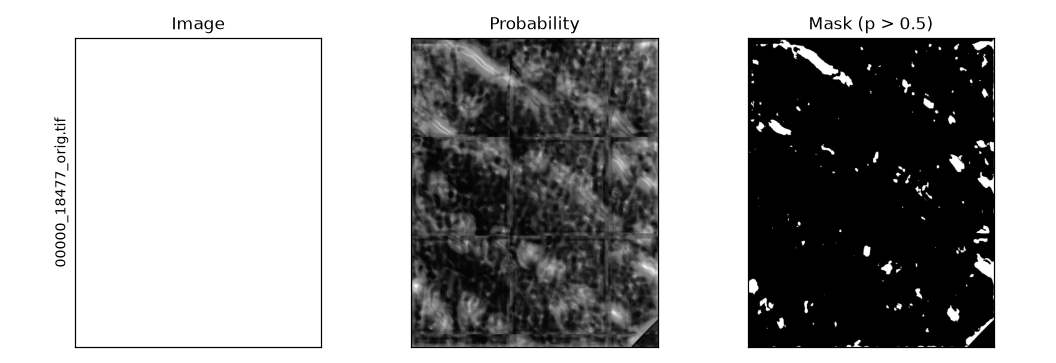

The figure shows the original micrograph, the probability map, and the mask at threshold 0.5 side by side.

In [5]:
%%ask
Segment the mitochondria in record 18477 with the most suitable pretrained model, and 
show the result.

## 5. A large dataset

In [6]:
%%ask
Download the full original data of record 49418.

The full original dataset is 9.7 GB, which is above the 2 GB threshold, so nothing was downloaded — it needs your go-ahead first.

## CIL_49418: Mus musculus, embryonic cell

Citation: Babette Hammerling, Rita Najor, Melissa Cortez, Sarah Shires, Leonardo Leon, Eileen Gonzalez, Daniela Boassa, Sébastien Phan, Andrea Thor, Rebecca Jimenez, Hong Li, Richard Kitsis, Gerald Dorn, Junichi Sadoshima, Mark Ellisman, Asa Gustafsson (2016) CIL:49418, Mus musculus, embryonic cell. CIL. Dataset

Mitochondria are sequestered inside Rab5+ endosomes after FCCP treatment in WT and Atg5-/- MEFs. Wild-type (WT) and Atg5-/- mouse embryonic fibroblasts (MEFs) were transfected with GFP-Rab5, nanobody against GFP (VHH)-APEX2, HA-Parkin, and mPlum-mito-3 using Fugene 6. Cells were treated with DMSO or 25 uM FCCP for 4 hours and fixed with 2.5% gluteraldehyde. Cells were imaged by confocal microscopy and subsequently processed and imaged for transmission electron microscopy. Colocalizing puncta found by confocal microscopy, indicating mPlum-mito-3+ mitochondria within GFP-Rab5+ early endosomes, were correlated to their location in the electron micrographs. Tomograms were acquired of these locations, which morphological confirm the presence of mitochondria within single-membraned early endosomes.

| | |
|---|---|
| Kind | image, Z-stack |
| Imaging | scanning electron microscopy (SEM) |
| Cellular component | endosome; mitochondria |
| Cell type | embryonic cell |
| Organism | Mus musculus |
| Dimensions (pixels) | — |
| Pixel size (as recorded) | — |
| Terms of use | public domain |
| Contributors | Babette Hammerling; Rita Najor; Melissa Cortez; Sarah Shires; Leonardo Leon; Eileen Gonzalez; Daniela Boassa; Sébastien Phan; Andrea Thor; Rebecca Jimenez; Hong Li; Richard Kitsis; Gerald Dorn; Junichi Sadoshima; Mark Ellisman; Asa Gustafsson |
| DOI | 10.7295/W9CIL49418 |
| Page | https://www.cellimagelibrary.org/images/49418 |

**Files**

| File | Type | Size | Address |
|---|---|---|---|
| 49418.tif | OME_tif | 1.6 MB | https://cildata.crbs.ucsd.edu/media/images/49418/49418.tif |
| 49418.jpg | Jpeg | 154.0 KB | https://cildata.crbs.ucsd.edu/media/images/49418/49418.jpg |
| 49418.zip | Zip | 294.3 KB | https://cildata.crbs.ucsd.edu/media/images/49418/49418.zip |
| pid-20381-for_ccdb.tar.gz (extra) | Gzip | 9.7 GB | https://cildata.crbs.ucsd.edu/ftp/data/telescience/home/CCDB_DATA_USER.portal/CCDB_DATA_USER/acquisition/project_20381/pid-20381-for_ccdb.tar.gz |

The ZIP holds the data as submitted to CIL and the TIFF is CIL's converted copy; an extra file, when there is one, is often the full original dataset. Pixel sizes are as the contributor recorded them.

## Download: CIL_49418

Terms of use: public domain.

pid-20381-for_ccdb.tar.gz is 9.7 GB (1790.0 GB free in `/tmp/cil/49418`). Nothing has been downloaded; it starts only when you confirm.

---

**To proceed** : the full original dataset is a single 9.7 GB gzipped tar archive (`pid-20381-for_ccdb.tar.gz`) — the whole acquisition project behind this record, not just the one published image. Say the word and I'll start the download; it goes to `/tmp/cil/49418`, which is temporary storage that is lost when the pod stops, and an interrupted download resumes where it left off if re-run. The record itself is public domain, so there are no reuse restrictions. If you only need the published image, the 1.6 MB TIFF or the 294 KB ZIP (containing `49418_orig.png`) are already small enough to fetch immediately.

## 6. CDeep3M Store

In [7]:
%%ask
What is CDeep3M storing for this project, and how much space does it take?

## CDeep3M storage

**Kept** in `/home/jovyan/work/_User-Persistent-Storage_CephBlock_/Sage_demo/cdeep3m` (persistent storage: survives pod restarts, counts against the quota): **273 MB** , 1.8 GB free.

| What | Name | Size | Last changed |
|---|---|---|---|
| trained model | mito_finetuned_300 | 193 MB | 2026-11-20 22:11 |
| prediction | val_mito_pretrained | 28 MB | 2026-11-20 21:55 |
| prediction | val_mito_finetuned | 28 MB | 2026-11-20 22:13 |
| prediction | mito_18477 | 25 MB | 2026-11-22 00:02 |

**Temporary** in `/tmp/cdeep3m` (lost when the pod stops; pretrained models download again on use): **781 MB** , 1788.7 GB free.

| What | Name | Size | Last changed |
|---|---|---|---|
| downloaded pretrained model | sbem-mitochondria | 781 MB | 2026-11-21 23:51 |

Anything listed can be deleted by name; nothing is deleted without the user's confirmation.

In total that is about 1.05 GB — 273 MB of it persistent and 781 MB temporary.

In [8]:
%%ask
Delete the prediction cil18477_mito.

The name you gave doesn't exist in storage — the prediction from record 18477 was saved as `mito_18477`, not `cil18477_mito`. Here is what the delete preview found.

## Delete

- `cil18477_mito`: not found (the storage report lists what there is)

## Delete

| What | Name | Size | Where |
|---|---|---|---|
| prediction | mito_18477 | 25 MB | persistent storage |

Nothing has been deleted. This frees 25 MB; it happens only when the user confirms.

---

**Nothing was deleted.** `cil18477_mito` is not a name CDeep3M has on record, so there was nothing to remove under that name. The prediction you most likely mean is **`mito_18477`** — the mitochondria segmentation of CIL 18477 I ran earlier, 25 MB in persistent storage. It is the only prediction in the project that corresponds to record 18477.

**To proceed** : confirm that `mito_18477` is the one you want gone, and I'll delete it. The other two predictions, `val_mito_pretrained` and `val_mito_finetuned` (28 MB each), and the trained model `mito_finetuned_300` (193 MB) are untouched either way.